# 05 · Explainability: SHAP, LIME and partial dependence

Explains the interface model (BRFSS binary, Gradient Boosting) from notebook 04.

1. **Global:** which features matter most overall (SHAP)
2. **Feature effects:** how risk changes as one feature changes (partial dependence and SHAP dependence)
3. **Local:** why the model gave three example people their risk (SHAP and LIME)
4. **Agreement:** do SHAP and LIME point to the same reasons? (200 people)
5. **Stability and speed:** does LIME give the same answer twice, and how long does each method take?

Explanations use people from the **test set**, so they describe how the model behaves on people it was not trained on. SHAP values are on the **log-odds** scale: positive values push towards diabetes, negative values push away from it.

In [1]:
import sys, json, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings('ignore')

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from src.explain import (agreement, describe_value, label, lime_explainer, lime_weights, partial_dependence,
                         preprocess, shap_explainer, shap_values)
from src.preprocess import RANDOM_STATE

PROCESSED, FIG_DIR, MODEL_DIR = ROOT / 'data/processed', ROOT / 'reports/figures', ROOT / 'models'
pipe = joblib.load(MODEL_DIR / 'interface_brfss_bin_gb.joblib')
meta = json.loads((MODEL_DIR / 'interface_brfss_bin_gb.json').read_text())
TARGET = 'Diabetes_binary'
train = pd.read_csv(PROCESSED / 'brfss_bin_train.csv'); test = pd.read_csv(PROCESSED / 'brfss_bin_test.csv')
X_tr, X_te, y_te = train.drop(columns=TARGET), test.drop(columns=TARGET), test[TARGET]
sample = X_te.sample(2000, random_state=RANDOM_STATE)
explainer = shap_explainer(pipe)
exp = shap_values(pipe, sample, explainer)
shap_df = pd.DataFrame(exp.values, columns=sample.columns, index=sample.index)
print('Model:', meta['model'], '| threshold', meta['threshold'], '| explained people:', len(sample))

Model: Gradient Boosting (HistGradientBoostingClassifier) | threshold 0.28 | explained people: 2000


## 1 · Global importance (SHAP)

The bar chart shows the average size of each feature's effect. The beeswarm shows every person as a dot: red means a high value of the feature, and dots to the right mean higher risk.

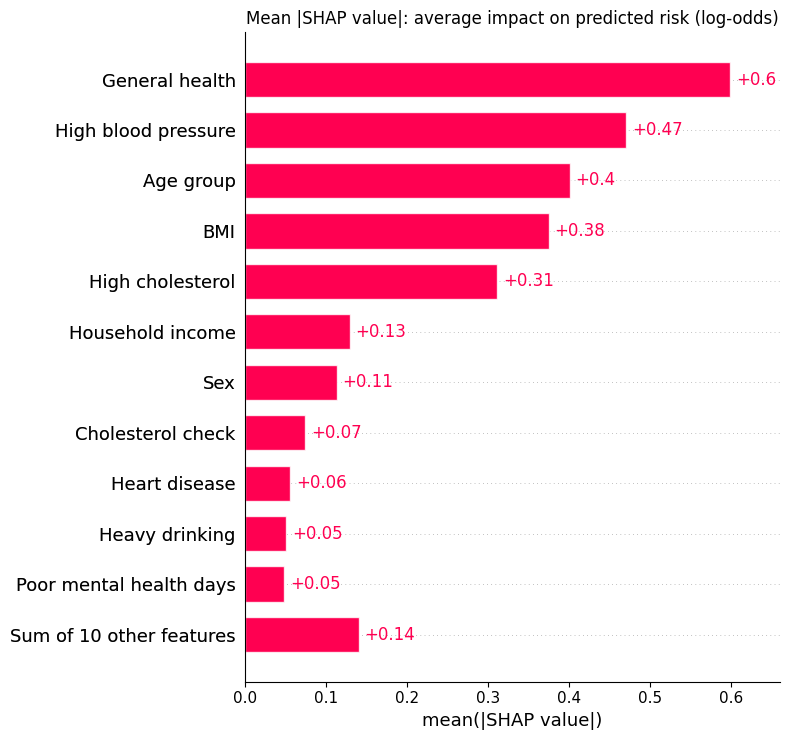

In [2]:
plt.figure()
shap.plots.bar(exp, max_display=12, show=False)
plt.title('Mean |SHAP value|: average impact on predicted risk (log-odds)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'xai_shap_bar.png', dpi=200, bbox_inches='tight'); plt.show()

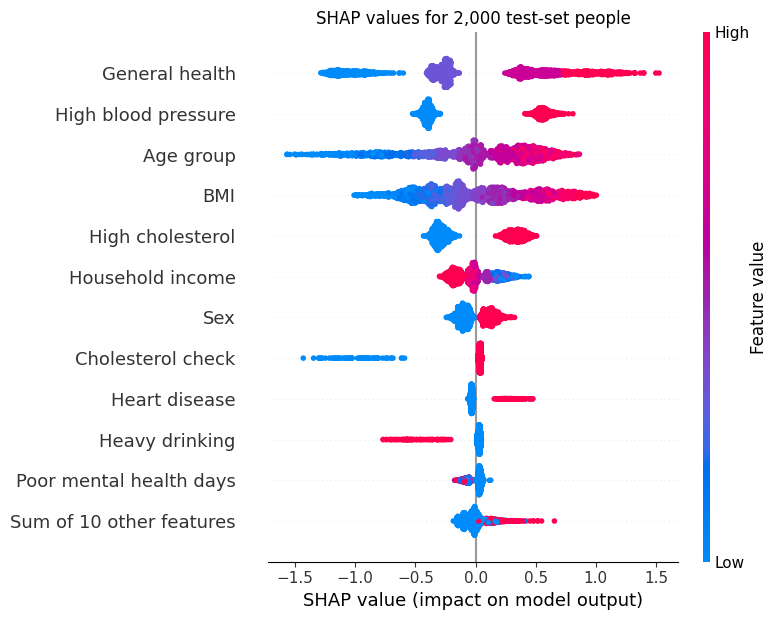

In [3]:
plt.figure()
shap.plots.beeswarm(exp, max_display=12, show=False)
plt.title('SHAP values for 2,000 test-set people')
plt.tight_layout(); plt.savefig(FIG_DIR / 'xai_shap_beeswarm.png', dpi=200, bbox_inches='tight'); plt.show()

### Sanity check against the data

If the model has learned sensible patterns, its most important features should broadly match the features most strongly linked to diabetes in the EDA.

In [4]:
full = pd.concat([X_te, y_te], axis=1)
corr = full.corr(method='spearman')[TARGET].drop(TARGET)
ranks = pd.DataFrame({
    'Feature': [label(c) for c in X_te.columns],
    'SHAP rank': shap_df.abs().mean().rank(ascending=False).astype(int).values,
    'Correlation rank': corr.abs().rank(ascending=False).astype(int).values,
    'Correlation': corr.round(3).values,
}).sort_values('SHAP rank')
print('Spearman correlation between the two rankings:', round(ranks[['SHAP rank', 'Correlation rank']].corr(method='spearman').iloc[0, 1], 3))
ranks.head(10)

Spearman correlation between the two rankings: 0.671


,Feature,SHAP rank,Correlation rank,Correlation
13,General health,1,1,0.286
0,High blood pressure,2,2,0.262
18,Age group,3,6,0.178
3,BMI,4,3,0.218
1,High cholesterol,5,5,0.198
20,Household income,6,8,-0.161
17,Sex,7,18,0.033
2,Cholesterol check,8,14,0.062
6,Heart disease,9,7,0.174
10,Heavy drinking,10,16,-0.057


## 2 · How risk changes with each feature

**Partial dependence (PDP)** shows the model's average predicted probability as one feature changes, with everything else held at each person's real values. The thin lines (ICE) show individuals.

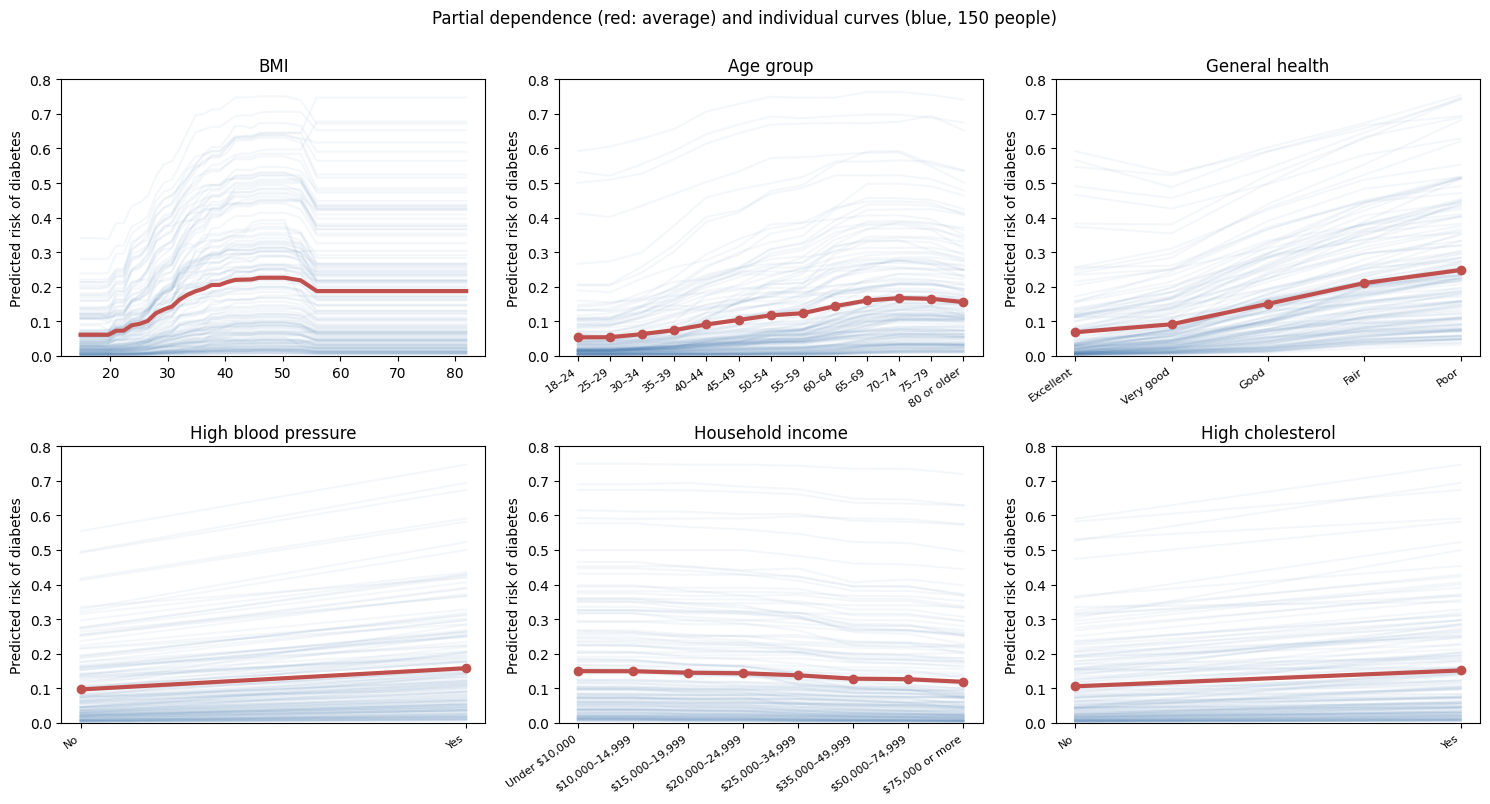

In [5]:
features = ['BMI', 'Age', 'GenHlth', 'HighBP', 'Income', 'HighChol']
pdp_sample = X_te.sample(1000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), features):
    grid, avg, ice = partial_dependence(pipe, pdp_sample, f)
    ax.plot(grid, ice[:150].T, color='#4A7FB5', alpha=0.06)
    ax.plot(grid, avg, color='#C0504D', lw=3, marker='o' if len(grid) <= 13 else None)
    if len(grid) <= 13:
        ax.set_xticks(grid, [describe_value(f, v) for v in grid], rotation=35, ha='right', fontsize=8)
    ax.set_title(label(f)); ax.set_ylabel('Predicted risk of diabetes'); ax.set_ylim(0, 0.8)
fig.suptitle('Partial dependence (red: average) and individual curves (blue, 150 people)', y=1.0)
plt.tight_layout(); plt.savefig(FIG_DIR / 'xai_pdp.png', dpi=200, bbox_inches='tight'); plt.show()

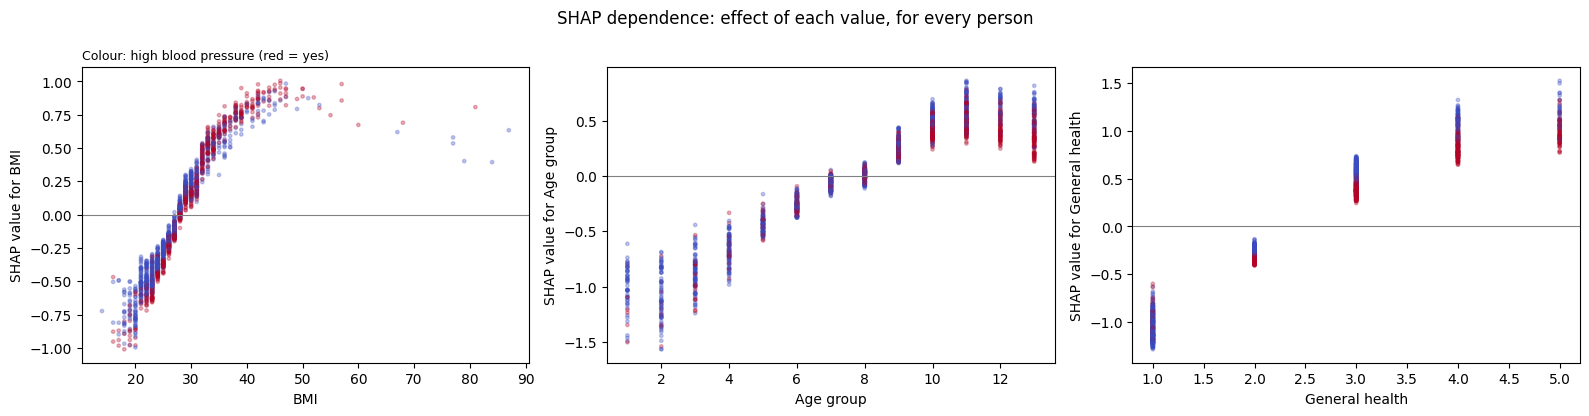

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, f in zip(axes, ['BMI', 'Age', 'GenHlth']):
    ax.scatter(sample[f], shap_df[f], s=6, alpha=0.3, c=sample['HighBP'], cmap='coolwarm')
    ax.axhline(0, c='grey', lw=0.8); ax.set_xlabel(label(f)); ax.set_ylabel(f'SHAP value for {label(f)}')
axes[0].set_title('Colour: high blood pressure (red = yes)', fontsize=9, loc='left')
plt.suptitle('SHAP dependence: effect of each value, for every person'); plt.tight_layout()
plt.savefig(FIG_DIR / 'xai_shap_dependence.png', dpi=200, bbox_inches='tight'); plt.show()

## 3 · Explaining three individual people

Three test-set people chosen by predicted risk: **low** (about 3%), **borderline** (around the 28% threshold) and **high** (about 60%).

In [7]:
proba = pipe.predict_proba(X_te)[:, 1]
def nearest(p):
    return X_te.index[np.argmin(np.abs(proba - p))]
people = {'Low risk': nearest(0.03), 'Borderline': nearest(meta['threshold']), 'High risk': nearest(0.60)}
profile = pd.DataFrame({name: {label(c): describe_value(c, X_te.loc[i, c]) for c in X_te.columns}
                        for name, i in people.items()})
profile.loc['Predicted risk'] = [f'{proba[X_te.index.get_loc(i)]:.0%}' for i in people.values()]
profile.loc['Actually has diabetes'] = ['Yes' if y_te[i] else 'No' for i in people.values()]
profile

,Low risk,Borderline,High risk
High blood pressure,Yes,Yes,Yes
High cholesterol,No,No,Yes
Cholesterol check,Yes,Yes,Yes
BMI,33,42,33
Smoker,Yes,No,Yes
Stroke,No,No,Yes
Heart disease,No,No,Yes
Physical activity,Yes,Yes,No
Eats fruit daily,Yes,Yes,No
Eats vegetables daily,Yes,No,Yes


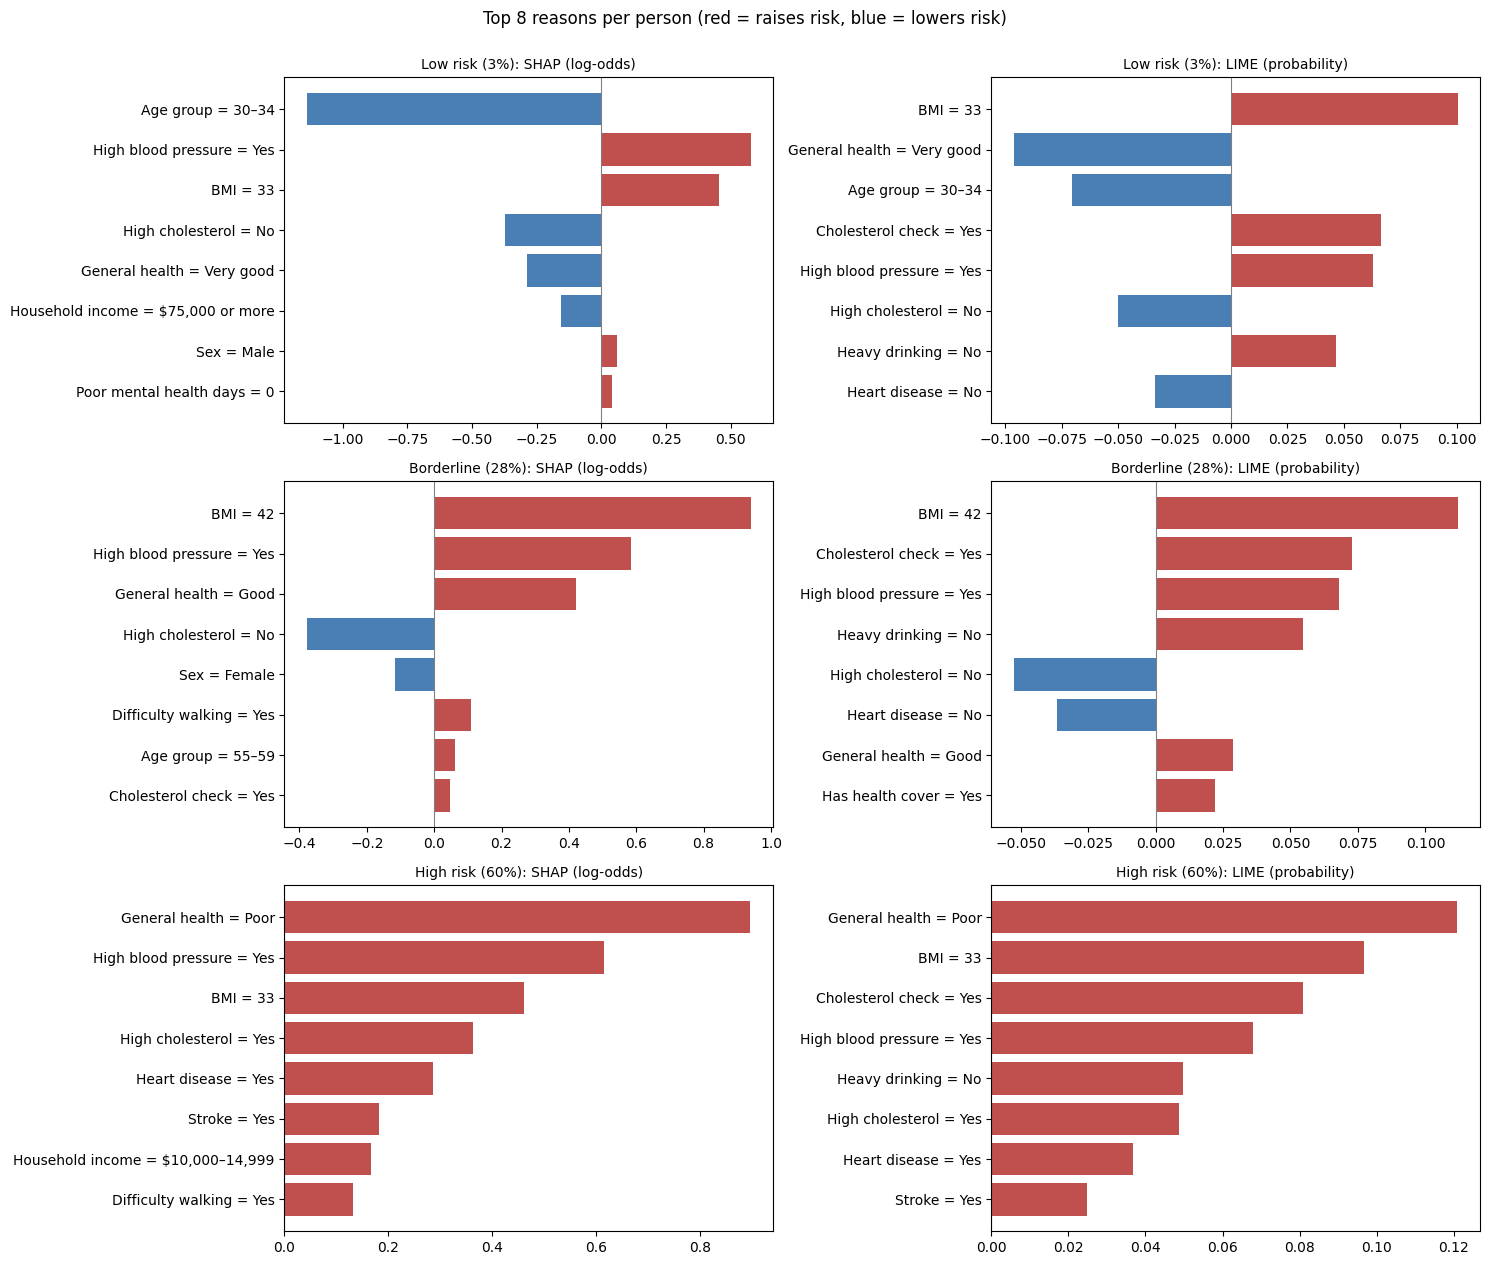

In [8]:
lime_exp = lime_explainer(pipe, X_tr.sample(5000, random_state=RANDOM_STATE))
local = {}
fig, axes = plt.subplots(len(people), 2, figsize=(15, 4.2 * len(people)))
for row, (name, i) in enumerate(people.items()):
    person = X_te.loc[[i]]
    s = pd.Series(shap_values(pipe, person, explainer).values[0], index=person.columns)
    l = lime_weights(pipe, lime_exp, person)
    local[name] = (s, l)
    for ax, (method, w) in zip(axes[row], (('SHAP (log-odds)', s), ('LIME (probability)', l))):
        top = w.reindex(w.abs().sort_values().index[-8:])
        ax.barh([f'{label(c)} = {describe_value(c, person[c].iloc[0])}' for c in top.index], top,
                color=['#C0504D' if v > 0 else '#4A7FB5' for v in top])
        ax.axvline(0, c='grey', lw=0.8)
        ax.set_title(f'{name} ({proba[X_te.index.get_loc(i)]:.0%}): {method}', fontsize=10)
plt.suptitle('Top 8 reasons per person (red = raises risk, blue = lowers risk)', y=1.0)
plt.tight_layout(); plt.savefig(FIG_DIR / 'xai_local_examples.png', dpi=200, bbox_inches='tight'); plt.show()

In [9]:
for name, (s, l) in local.items():
    print(name, {k: round(v, 2) for k, v in agreement(s, l).items()})

Low risk {'top_k_overlap': 0.8, 'sign_agreement': 1.0, 'rank_corr': np.float64(0.79)}
Borderline {'top_k_overlap': 0.6, 'sign_agreement': 1.0, 'rank_corr': np.float64(0.61)}
High risk {'top_k_overlap': 0.6, 'sign_agreement': 1.0, 'rank_corr': np.float64(0.75)}


## 4 · Do SHAP and LIME agree? (200 test-set people)

- **Top-5 overlap:** share of each method's five most important features that the other also picks
- **Sign agreement:** for those shared features, do both say the feature raises (or lowers) risk?
- **Rank correlation:** Spearman correlation of feature importance across all 21 features

In [10]:
agree_people = X_te.sample(200, random_state=1)
rows, t_shap, t_lime, first_shap, first_lime = [], [], [], [], []
for i in agree_people.index:
    person = X_te.loc[[i]]
    t = time.time(); s = pd.Series(shap_values(pipe, person, explainer).values[0], index=person.columns); t_shap.append(time.time() - t)
    t = time.time(); l = lime_weights(pipe, lime_exp, person); t_lime.append(time.time() - t)
    rows.append(agreement(s, l))
    first_shap.append(label(s.abs().idxmax())); first_lime.append(label(l.abs().idxmax()))
agree = pd.DataFrame(rows)
print(agree.describe().loc[['mean', '50%', 'std', 'min']].round(3))
print(f'\nTime per person: SHAP {np.mean(t_shap) * 1000:.0f} ms, LIME {np.mean(t_lime) * 1000:.0f} ms')

      top_k_overlap  sign_agreement  rank_corr
mean          0.697             1.0      0.736
50%           0.800             1.0      0.741
std           0.113             0.0      0.064
min           0.400             1.0      0.570

Time per person: SHAP 2 ms, LIME 36 ms


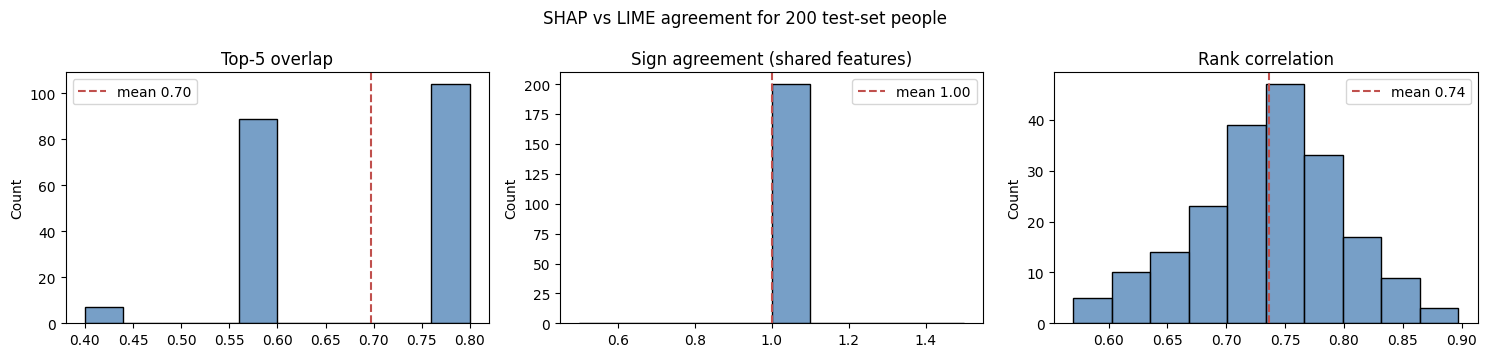

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col, title in zip(axes, agree.columns, ['Top-5 overlap', 'Sign agreement (shared features)', 'Rank correlation']):
    sns.histplot(agree[col].dropna(), bins=10, ax=ax, color='#4A7FB5')
    ax.axvline(agree[col].mean(), c='#C0504D', ls='--', label=f'mean {agree[col].mean():.2f}')
    ax.set_title(title); ax.set_xlabel(''); ax.legend()
plt.suptitle('SHAP vs LIME agreement for 200 test-set people'); plt.tight_layout()
plt.savefig(FIG_DIR / 'xai_agreement.png', dpi=200, bbox_inches='tight'); plt.show()

In [12]:
pd.DataFrame({'SHAP': pd.Series(first_shap).value_counts(), 'LIME': pd.Series(first_lime).value_counts()}).fillna(0).astype(int).sort_values('SHAP', ascending=False).rename_axis('Most important feature for a person')

,SHAP,LIME
Most important feature for a person,,
General health,80,154
Age group,43,4
High blood pressure,39,1
BMI,31,12
Cholesterol check,5,28
Heavy drinking,2,0
High cholesterol,0,1


## 5 · Is LIME stable?

LIME uses random sampling, so explaining the same person twice can give different answers. Each of the three example people is explained 10 times with different random seeds. SHAP (TreeExplainer) is exact for tree models and always gives the same answer.

In [13]:
from lime.lime_tabular import LimeTabularExplainer
stab_rows = []
bg = X_tr.sample(5000, random_state=RANDOM_STATE)
for name, i in people.items():
    person = X_te.loc[[i]]
    tops = []
    for seed in range(10):
        le = lime_explainer(pipe, bg); le.random_state = np.random.RandomState(seed)
        w = lime_weights(pipe, le, person)
        tops.append(frozenset(w.abs().nlargest(5).index))
    base = tops[0]
    stab_rows.append({'Person': name, 'Distinct top-5 sets in 10 runs': len(set(tops)),
                      'Mean overlap with first run': np.mean([len(base & t) / 5 for t in tops[1:]])})
pd.DataFrame(stab_rows).set_index('Person').round(2)

,Distinct top-5 sets in 10 runs,Mean overlap with first run
Person,,
Low risk,2,0.80
Borderline,1,1.00
High risk,2,0.89


## Findings

**1. What drives the model overall (SHAP).** The five most important features are general health, high blood pressure, age, BMI and high cholesterol, matching the strongest relationships found in the EDA (the two rankings correlate at 0.67). Sex ranks 7th for SHAP but 18th by simple correlation, so the model uses it mainly in combination with other features.

**2. Feature effects (partial dependence).** On average, predicted risk rises from about 6% at BMI 20 to about 22% at BMI 45–50. It rises steadily with age up to 70–74 and falls slightly after. It rises from about 7% to 25% from "excellent" to "poor" general health. High blood pressure and high cholesterol each add about 5 percentage points on average, and higher income slightly lowers risk. The BMI curve is flat above about 55 because the pipeline caps extreme BMI values. The individual (ICE) curves show the same change matters much more for some people than others.

**3. Some effects are associations, not causes.** Heavy drinking *lowers* predicted risk, and *not* having had a cholesterol check lowers it too. These are patterns in the survey, not advice. People who have never had a cholesterol check have less contact with doctors, so are less likely to have been diagnosed. Heavy drinking may be less common among people who have already been told they have diabetes. **The interface must not present these as things to change.**

**4. SHAP and LIME mostly agree (200 test-set people).**

| Measure | Mean | Median | Minimum |
|---|---|---|---|
| Top-5 overlap | 0.70 | 0.80 | 0.40 |
| Sign agreement (shared features) | 1.00 | 1.00 | 1.00 |
| Rank correlation | 0.74 | 0.74 | 0.57 |

When both methods pick a feature, they **always** agree on whether it raises or lowers risk. They differ in emphasis: LIME names general health as the single most important feature for 154 of 200 people (SHAP: 80), and it gives more weight to yes/no features such as cholesterol check. SHAP spreads importance more evenly across age, blood pressure and BMI.

**5. Speed and stability.** SHAP takes about **2 ms** per person and is exact, so it always gives the same answer. LIME takes about **36 ms** and is random. Over 10 runs per person, the top-5 features stayed mostly the same (1–2 different sets, 80–100% overlap), but they can change.

**Decision for the interface:** use **SHAP** for the main explanation because it is exact, fast and stable. Show the top reasons in plain language, and keep LIME as an optional "second opinion" for the user study. Only suggest changes to factors a person can realistically change, such as BMI and physical activity. Label other factors as "linked to risk in the survey data".
